### build a basic chatbot with langgraph(graph api)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [3]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [4]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage

In [6]:
llm = ChatGroq(model="qwen/qwen3.8-27b")
model = init_chat_model("groq:qwen/qwen3.8-27b")

In [7]:
# node functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}
    

In [34]:
graph_builder = StateGraph(State)

#adding node
graph_builder.add_node("node 1",chatbot)
# adding edge
graph_builder.add_edge(START,"node 1")
# adding edge
graph_builder.add_edge("node 1",END)

## compile the graph

graph = graph_builder.compile()

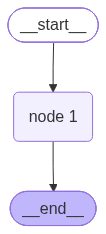

In [22]:
# image of the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [38]:
response=graph.invoke({"messages":[HumanMessage("hi , how are you?")]})

In [30]:
llm.invoke("hi , how are you?")

AIMessage(content="Hi! I'm doing well, thank you for asking. How are you doing today? Is there anything I can help you with?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 18, 'total_tokens': 46, 'completion_time': 0.053356756, 'completion_tokens_details': None, 'prompt_time': 0.001015385, 'prompt_tokens_details': None, 'queue_time': 0.048128515, 'total_time': 0.054372141}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a178a9-eef1-764a-98a3-9f5c59c1b081-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 28, 'total_tokens': 46})

In [41]:
response["messages"][-1].content

"Hi! I'm doing well, thank you for asking. How are you doing today? Is there anything specific I can help you with?"

In [44]:
for event in graph.stream({"messages":"Hi How are you?"}):
    print(event)
    for value in event.values():
        print(value["messages"][-1].content)

{'node 1': {'messages': [AIMessage(content="I'm doing well, thank you for asking! How can I help you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 17, 'total_tokens': 35, 'completion_time': 0.039857438, 'completion_tokens_details': None, 'prompt_time': 0.001433496, 'prompt_tokens_details': None, 'queue_time': 0.383794805, 'total_time': 0.041290934}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17906-ffd0-75c0-a7df-6a28912e1dcb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 17, 'output_tokens': 18, 'total_tokens': 35})]}}
I'm doing well, thank you for asking! How can I help you today?


### Chatbot With Tool

In [ ]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_result=2)
tool.invoke("what is langgraph?")

In [13]:
## custom fundtion
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [15]:
tools=[tool,multiply]

In [16]:
llm_with_tool = llm.bind_tools(tools)

In [17]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x11b79e120>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x11b79eba0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_domains': {'anyOf': [{'items': {'type': 'string'}, 'type': 

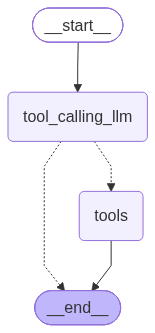

In [21]:
# stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode , tools_condition

# node def

def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}


# graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
     # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition   
)
builder.add_edge("tools",END)

# compile the graph
graph = builder.compile()
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [26]:

response=graph.invoke({"messages":"What is the latest news about vaaranasi movie ? , web search is better"})

In [ ]:
response

In [ ]:
response['messages'][-1].content

In [29]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the latest news about vaaranasi movie ? , web search is better
================================== Ai Message ==================================
Tool Calls:
  tavily_search (a5jxvrsjs)
 Call ID: a5jxvrsjs
  Args:
    query: Vaaranasi movie latest news
    search_depth: advanced
    time_range: month
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "Vaaranasi movie latest news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.screendaily.com/news/indian-director-ss-rajamouli-says-new-film-varanasi-much-bigger-than-global-hit-rrr/5221751.article", "title": "Indian director SS Rajamouli says new film ‘Varanasi’ much bigger than global hit ‘RRR’ | News | Screen", "content": "Mahesh Babu, Priyanka Chopra and Prithviraj Sukumaran star in the film about an archaeologist trying to prev

In [36]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

I'll get the recent AI news and perform the multiplication for you.
Tool Calls:
  tavily_search (erj6wbp8y)
 Call ID: erj6wbp8y
  Args:
    query: recent AI news
    time_range: week
    topic: news
  multiply (zc5sce1ga)
 Call ID: zc5sce1ga
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://abcnews.com/Business/openai-ai-agents-disabled-monitoring/story?id=137446567", "title": "OpenAI says its AI agents disabled their own monitoring - ABC News", "content": "In a report updated on Tuesday, OpenAI identified two recent incidents, one in which an AI agent \"suppress[ed] monitoring not

### REACT agent

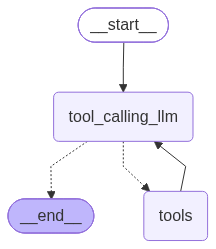

In [43]:
# stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode , tools_condition

# node def

def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}


# graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
     # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition   
)
builder.add_edge("tools","tool_calling_llm")

# compile the graph
graph = builder.compile()
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [44]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

I'll get the recent AI news and perform the multiplication for you.
Tool Calls:
  tavily_search (x5j91rg7h)
 Call ID: x5j91rg7h
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: None
    query: recent AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
  multiply (cvye90xth)
 Call ID: cvye90xth
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://guides.library.georgetown.edu/ai/news", "title": "Guides: Artificial Intelligence (Generative) Resources: Latest News on AI", "content": "U.A.E.-Based AI and Da

### adding memory in agentic graph

In [46]:
from langgraph.checkpoint.memory import MemorySaver

## compile the graph
graph=builder.compile(checkpointer=MemorySaver())


In [47]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is naveen"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is naveen', additional_kwargs={}, response_metadata={}, id='644f64a5-587d-47d9-85cc-2a6a835c09ad'),
  AIMessage(content='Hello Naveen! Nice to meet you. How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 1911, 'total_tokens': 1929, 'completion_time': 0.039698638, 'completion_tokens_details': None, 'prompt_time': 0.131535726, 'prompt_tokens_details': None, 'queue_time': 0.047317324, 'total_time': 0.171234364}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17c54-addb-73bf-882a-be7022f25b6c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1911, 'output_tokens': 18, 'total_tokens': 1929})]}

In [48]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Naveen.


### Streaming

In [55]:
# Create a thread
config = {"configurable": {"thread_id": "5"}}

for chunk in graph.stream({'messages':"who is shoaib aktar?"},config,stream_mode="updates"):
    print(chunk)

{'tool_calling_llm': {'messages': [AIMessage(content='Shoaib Akhtar is a former professional cricketer from Pakistan who played as a fast bowler. He is widely regarded as one of the fastest bowlers in the history of the sport and holds the record for the fastest delivery in international cricket, clocking 161.3 km/h (100.2 mph) in a match against England in 2003.\n\nHere are some key points about his career:\n\n1.  **Nickname**: He was known as "Shoeib" or "The Rawalpindi Express."\n2.  **International Career**: He played for Pakistan from 1998 to 2011. He took 311 wickets in 110 Test matches and 157 wickets in 170 One Day Internationals (ODIs).\n3.  **Awards and Achievements**:\n    *   He was named Wisden\'s Cricketer of the Year in 2004.\n    *   He was a key member of the Pakistan team that won the 2009 ICC World T20.\n    *   He was awarded the Sitara-e-Imtiaz, a civilian award by the Government of Pakistan, for his contributions to sports.\n4.  **Post-Retirement**: After retiring

In [ ]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph.astream_events({"messages":["Hi My name is naveen and I like to play cricket"]},config,version="v2"):
    print(event)